# AMO Encodings và Solver Approaches cho Sudoku

Notebook này đọc `benchmark_results.csv` (1.899 lượt chạy = 9 phương pháp × 211 instance) và tạo:

| Mục | Nội dung | File xuất ra | Vị trí trong `main.tex` |
|---|---|---|---|
| Hình 2 | Cactus plot của 5 AMO encoding | `figures/cactus_sat_encodings.pdf` | §4.2 |
| Hình 3 | Thời gian dựng công thức so với thời gian giải | `figures/encoding_vs_solving.pdf` | §4.2 |
| Hình 4 | Cactus plot của 5 phương pháp (SAT, CP, MIP) | `figures/cactus_solvers.pdf` | §4.3 |
| Hình 5 | Thời gian trung vị theo hole ratio, mỗi $N$ một ô | `figures/time_by_hole_ratio.pdf` | §4.3 |
| Hình 6 | Scatter log-log, từng phương pháp so với `sat_product` | `figures/scatter_loglog_pairs.pdf` | §4.3 |
| Bảng 3–6 | Kích thước CNF, số instance giải được, so sánh solver, instance không đồng nhất | `tables/*.csv` | §4.2, §4.3 |
| Kiểm tra | Đối chiếu các con số trích trong Abstract/Conclusion với dữ liệu | in ra màn hình | — |

**Cấu trúc notebook.** `0` Dữ liệu và quy ước → `1` Cấu hình chung → `2` Hình 2–6 → `3` Bảng → `4` Kiểm tra số liệu.
Mỗi hình có một ô markdown giải thích *vẽ gì*, *đọc thế nào* và *lưu ý*, theo sau là ô code; số liệu nêu trong phần giải thích đều được **in ra từ dữ liệu**, không gõ tay.

## 0. Dữ liệu và quy ước

### 0.1 Các cột của CSV

| Cột gốc | Tên trong notebook | Ý nghĩa |
|---|---|---|
| `N` | `N` | Cấp lưới ($N=B^2$, từ 9 đến 81) |
| `Hole Ratio` | `hole` | Tỉ lệ ô trống $\rho$ |
| `Seed` | `Seed` | Seed của bộ sinh instance |
| `Method` | `m` | Phương pháp: 5 SAT encoding (`sat_*`), `cpsat`, `cplex_cp`, `cplex_mip`, `gurobi` |
| `Status` | `st` | `SOLVED`, `TIMEOUT` hoặc `UNSOLVED` |
| `Encoding Time (s)` | `enc` | Thời gian dựng CNF hoặc mô hình |
| `Solving Time (s)` | `sol` | Thời gian bộ giải chạy |
| `Total Time (s)` | `tot` | `enc + sol` |
| `Vars`, `Constraints` | `vars`, `cons` | Số biến và số clause/ràng buộc của công thức |

Một **instance** là bộ ba `(N, hole, Seed)`; mỗi instance có đúng 9 dòng (một dòng cho mỗi phương pháp).

### 0.2 Quy ước dùng xuyên suốt

- **Thất bại** là `TIMEOUT` hoặc `UNSOLVED` (14 dòng `UNSOLVED` đều thuộc `cplex_mip`); chúng được xử lý như nhau.
- **Thời gian dùng để vẽ** `y` bằng `tot` với lần chạy giải được và bằng **600 s** $=2T$ với lần thất bại ($T=300$ s). Đây cũng là mức phạt của PAR2, nên biểu đồ và PAR2 nhất quán.
- Cactus plot chỉ vẽ các lần chạy **giải được**; scatter và đồ thị theo hole ratio dùng `y` (nên thất bại nằm ở 600 s, nhãn `fail`).

In [19]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from pathlib import Path

# ---------- Tìm và đọc dữ liệu ----------
cwd = Path.cwd()
candidates = [cwd / "benchmark_results.csv",
              cwd / "results" / "benchmark_results.csv",
              cwd.parent / "results" / "benchmark_results.csv",
              cwd.parent / "benchmark_results.csv"]
data_path = next((p.resolve() for p in candidates if p.is_file()), None)
if data_path is None:
    raise FileNotFoundError(f"Không tìm thấy benchmark_results.csv (thư mục hiện tại: {cwd})")

OUT = data_path.parent / "figures"      # hình
TAB = data_path.parent / "tables"       # bảng
OUT.mkdir(exist_ok=True); TAB.mkdir(exist_ok=True)

raw = pd.read_csv(data_path, encoding="utf-8-sig")
d = raw.rename(columns={"Hole Ratio": "hole", "Method": "m", "Status": "st",
                        "Encoding Time (s)": "enc", "Solving Time (s)": "sol",
                        "Total Time (s)": "tot", "Vars": "vars", "Constraints": "cons"})
d["st"]   = d["st"].astype(str).str.strip().str.upper()
d["hole"] = d["hole"].round(3)                # tránh sai số dấu phẩy động khi gộp nhóm
d["ok"]   = d["st"].eq("SOLVED")

TIMEOUT = 300.0                                # giới hạn thời gian (s)
FAIL_T  = 2 * TIMEOUT                          # mức phạt PAR2 / vị trí vẽ thất bại (600 s)
d["y"]  = np.where(d["ok"], d["tot"], FAIL_T)
KEY = ["N", "hole", "Seed"]                    # định danh một instance

# ---------- Kiểm tra tính toàn vẹn của dữ liệu ----------
n_inst = d.groupby(KEY).ngroups
assert not d.duplicated(KEY + ["m"]).any(), "Có dòng trùng (instance, method)"
assert (d.groupby(KEY)["m"].nunique() == d["m"].nunique()).all(), "Có instance thiếu phương pháp"
assert set(d["st"]) <= {"SOLVED", "TIMEOUT", "UNSOLVED"}, f"Status lạ: {set(d['st'])}"
assert np.allclose(d["tot"], d["enc"] + d["sol"], atol=1e-3), "tot != enc + sol"

print("CSV           :", data_path)
print("Hình / bảng   :", OUT, "|", TAB)
print(f"{len(d)} dòng = {n_inst} instance × {d['m'].nunique()} phương pháp")
print("Trạng thái    :", d["st"].value_counts().to_dict())
print("Instance theo N:", d.drop_duplicates(KEY).groupby("N").size().to_dict())

CSV           : D:\Study\Python\Sudoku_test\results\benchmark_results.csv
Hình / bảng   : D:\Study\Python\Sudoku_test\results\figures | D:\Study\Python\Sudoku_test\results\tables
1899 dòng = 211 instance × 9 phương pháp
Trạng thái    : {'SOLVED': 1775, 'TIMEOUT': 110, 'UNSOLVED': 14}
Instance theo N: {9: 65, 16: 36, 25: 26, 36: 25, 49: 19, 64: 21, 81: 19}


## 1. Cấu hình chung

- `SAT`: 5 AMO encoding chạy bằng Glucose 3 (qua PySAT). `B`: 5 phương pháp dùng để so sánh liên mô hình, trong đó **`sat_product` là đại diện SAT** (chọn theo quy tắc R1–R3 trong §4.2 của bài).

In [20]:
SAT = ["sat_pairwise", "sat_seqcounter", "sat_bitwise", "sat_commander", "sat_product"]
B   = ["cpsat", "sat_product", "gurobi", "cplex_cp", "cplex_mip"]   # SAT đại diện = product
NS  = sorted(d["N"].unique())

# Bảng màu Okabe-Ito (an toàn cho người mù màu)
COL = {"sat_pairwise": "#D55E00", "sat_seqcounter": "#CC79A7", "sat_bitwise": "#56B4E9",
       "sat_commander": "#E69F00", "sat_product": "#009E73",
       "cpsat": "#0072B2", "cplex_cp": "#D55E00", "gurobi": "#CC79A7", "cplex_mip": "#E69F00"}
MK  = {"sat_pairwise": "v", "sat_seqcounter": "s", "sat_bitwise": "^", "sat_commander": "D", "sat_product": "o",
       "cpsat": "o", "cplex_cp": "s", "gurobi": "^", "cplex_mip": "D"}
LS  = {"cpsat": "-", "sat_product": "-", "gurobi": "--", "cplex_cp": "-.", "cplex_mip": ":"}

plt.rcParams.update({
    "font.size": 8, "axes.titlesize": 8, "axes.labelsize": 8, "legend.fontsize": 7,
    "xtick.labelsize": 7, "ytick.labelsize": 7, "font.family": "DejaVu Sans",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": .25, "grid.linewidth": .5,
    "pdf.fonttype": 42, "figure.dpi": 110,
})

def save(fig, name):
    # Lưu PDF vector (cho LaTeX) và PNG (xem nhanh).
    fig.savefig(OUT / f"{name}.pdf")
    fig.savefig(OUT / f"{name}.png", dpi=200)
    plt.show()
    print("Đã lưu:", OUT / f"{name}.pdf")

def cactus(methods, fname, styles=None, title_legend="Method (solved)"):
    # Cactus plot: mỗi đường là thời gian đã sắp xếp của các lần chạy giải được.
    fig, ax = plt.subplots(figsize=(6.3, 3.2))
    for m in methods:
        t = np.sort(d[(d["m"] == m) & d["ok"]]["tot"].values)
        ax.plot(np.arange(1, len(t) + 1), t, label=f"{m} ({len(t)})",
                color=COL[m], lw=1.4, ls=(styles or {}).get(m, "-"))
    ax.axhline(TIMEOUT, color="gray", ls="--", lw=.8)
    ax.text(2, TIMEOUT * 1.1, f"{TIMEOUT:.0f} s limit", color="gray", fontsize=7)
    ax.set_yscale("log")
    ax.set_xlabel("Number of solved instances"); ax.set_ylabel("Total time (s, log scale)")
    ax.set_xlim(0, n_inst + 1); ax.set_ylim(2e-3, 1e3)
    ax.legend(title=title_legend, loc="upper left", frameon=False, bbox_to_anchor=(0, .93))
    fig.tight_layout(); save(fig, fname)

## 2. Các hình

### Hình 2: Cactus plot của 5 AMO encoding

 Với mỗi encoding, lấy thời gian tổng (dựng CNF + giải) của các instance đã giải, sắp xếp tăng dần; trục hoành là thứ hạng $k$ (số instance giải được), trục tung là thời gian của instance thứ $k$ (thang log).

 Đường **nằm thấp hơn** nghĩa là cùng số instance được giải trong thời gian ngắn hơn; đường **kéo dài sang phải hơn** nghĩa là giải được nhiều instance hơn. Số trong ngoặc ở chú giải là số instance giải được trên 211.

Cactus plot không so sánh được từng instance (mỗi đường sắp xếp độc lập), nên kết luận theo instance phải dựa vào tỉ lệ thời gian trong Bảng 4. Ở đây `sat_bitwise` dài hơn đúng một instance (36, 0.50, seed 4).

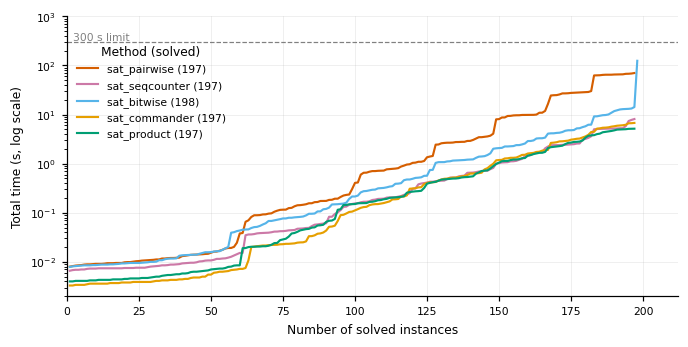

Đã lưu: D:\Study\Python\Sudoku_test\results\figures\cactus_sat_encodings.pdf
{'sat_pairwise': 197, 'sat_seqcounter': 197, 'sat_bitwise': 198, 'sat_commander': 197, 'sat_product': 197}


In [21]:
cactus(SAT, "cactus_sat_encodings")
print({m: int(d[(d['m'] == m) & d['ok']].shape[0]) for m in SAT})

### Hình 3: Thời gian dựng công thức so với thời gian giải (SAT, $N\ge 49$)

Với từng SAT encoding, trung bình thời gian **dựng CNF** (xám) và thời gian **giải** (cam) trên các lần chạy giải được có $N\ge 49$; số bên phải thanh là `enc + sol`.

Gần như toàn bộ thanh là phần xám: thời gian chủ yếu nằm ở việc sinh công thức bằng Python, không phải ở Glucose. Thứ tự các encoding theo tổng thời gian trùng với thứ tự theo thời gian dựng.

Chỉ dùng lần chạy giải được vì với SAT timeout, tách `enc`/`sol` không có nghĩa (timeout được ghi `enc=300`, `sol=0`). Kết quả phụ thuộc cài đặt Python của bộ dựng, không chỉ vào bản thân encoding.

Số lần chạy mỗi encoding: [49]
m
sat_product       19.4
sat_seqcounter    18.6
sat_commander     22.6
sat_bitwise       22.2
sat_pairwise      20.8
Name: tỉ lệ thời gian dựng / giải, dtype: float64


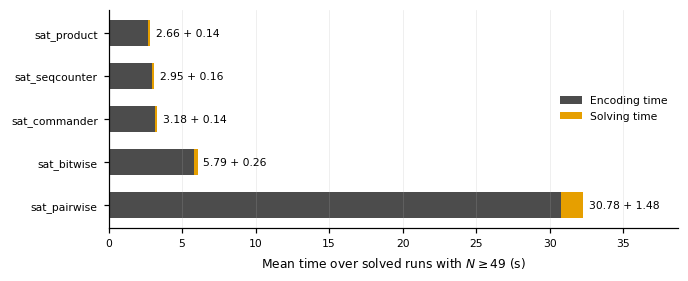

Đã lưu: D:\Study\Python\Sudoku_test\results\figures\encoding_vs_solving.pdf


In [22]:
order = ["sat_product", "sat_seqcounter", "sat_commander", "sat_bitwise", "sat_pairwise"]
sub = d[d["ok"] & (d["N"] >= 49) & d["m"].isin(SAT)]
e = sub.groupby("m")[["enc", "sol"]].mean().loc[order]
print(f"Số lần chạy mỗi encoding: {sub.groupby('m').size().unique()}")
print((e["enc"] / e["sol"]).round(1).rename("tỉ lệ thời gian dựng / giải"))

fig, ax = plt.subplots(figsize=(6.3, 2.6))
y = np.arange(len(e))
ax.barh(y, e["enc"], color="#4c4c4c", label="Encoding time", height=.6)
ax.barh(y, e["sol"], left=e["enc"], color="#E69F00", label="Solving time", height=.6)
for i, (m, r) in enumerate(e.iterrows()):
    ax.text(r["enc"] + r["sol"] + .4, i, f"{r['enc']:.2f} + {r['sol']:.2f}", va="center", fontsize=7)
ax.set_yticks(y); ax.set_yticklabels(e.index); ax.invert_yaxis()
ax.set_xlabel(r"Mean time over solved runs with $N\geq 49$ (s)")
ax.set_xlim(0, e[["enc", "sol"]].sum(axis=1).max() * 1.2)
ax.legend(frameon=False, loc="center right", bbox_to_anchor=(1, .55)); ax.grid(axis="y", visible=False)
fig.tight_layout(); save(fig, "encoding_vs_solving")

### Hình 4: Cactus plot của 5 phương pháp (SAT-product, CP-SAT, CPLEX CP, CPLEX MIP, Gurobi)

Cùng kiểu với Hình 2 nhưng cho 5 phương pháp thuộc ba mô hình: SAT (`sat_product`), CP (`cpsat`, `cplex_cp`) và MIP (`cplex_mip`, `gurobi`). Kiểu đường khác nhau để phân biệt khi in đen trắng.

Như Hình 2. `cpsat` là đường thấp nhất ở phần lớn dải và dài nhất (199 instance); `sat_product` thấp nhất với các instance nhỏ nhất.

 Mỗi đường nằm trên **tập instance giải được của riêng nó** (196–199 instance), nên thời gian giữa các phương pháp chỉ so sánh công bằng trên **tập chung** (196 instance được giải bởi cả năm) — xem Bảng 5.

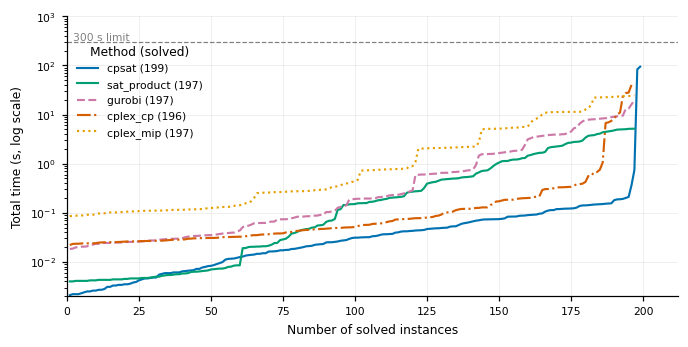

Đã lưu: D:\Study\Python\Sudoku_test\results\figures\cactus_solvers.pdf
{'cpsat': 199, 'sat_product': 197, 'gurobi': 197, 'cplex_cp': 196, 'cplex_mip': 197}


In [23]:
cactus(B, "cactus_solvers", styles=LS)
print({m: int(d[(d['m'] == m) & d['ok']].shape[0]) for m in B})

### Hình 5: Thời gian trung vị theo hole ratio, mỗi $N$ một ô

Mỗi ô là một cấp lưới $N$; trục hoành là hole ratio $\rho$, trục tung là **trung vị theo seed** của thời gian tổng (thang log). Ô cuối (trống) dùng làm chú giải.

Đường nằm trên mức `fail` (600 s) nghĩa là hơn một nửa số seed của nhóm đó thất bại. Quan sát chính: với $N\ge 49$ và $\rho\le 0{,}30$ mọi phương pháp giải nhanh; từ $\rho=0{,}40$ trở lên ở $N\ge 64$ không phương pháp nào giải được.

Tập $\rho$ **khác nhau giữa các $N$** và số seed mỗi cặp $(N,\rho)$ từ 1 đến 5, nên không so sánh trực tiếp độ dốc giữa các ô. Trung vị theo seed che đi sự phân tán giữa các seed.

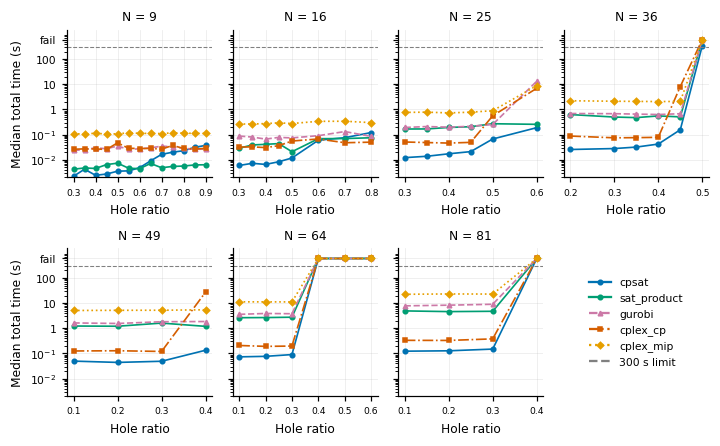

Đã lưu: D:\Study\Python\Sudoku_test\results\figures\time_by_hole_ratio.pdf


In [24]:
fig, axs = plt.subplots(2, 4, figsize=(6.6, 4.1), sharey=True)
for ax, N in zip(axs.flat, NS):
    q = d[(d["N"] == N) & d["m"].isin(B)]
    for m in B:
        r = q[q["m"] == m].groupby("hole")["y"].median()
        ax.plot(r.index, r.values, color=COL[m], ls=LS[m], marker=MK[m], ms=3, lw=1.1)
    ax.axhline(TIMEOUT, color="gray", ls="--", lw=.7)
    ax.set_yscale("log"); ax.set_title(f"N = {N}"); ax.set_xlabel("Hole ratio")
    ax.set_yticks([1e-3, 1e-2, 1e-1, 1, 10, 100, FAIL_T])
    ax.set_yticklabels(["$10^{-3}$", "$10^{-2}$", "$10^{-1}$", "1", "10", "100", "fail"])
    ax.set_ylim(2e-3, 1500)
    xs = sorted(q["hole"].unique())
    ax.set_xticks([x for x in xs if abs(x * 10 - round(x * 10)) < 1e-9]); ax.tick_params(axis="x", labelsize=6)
for a in axs[:, 0]: a.set_ylabel("Median total time (s)")
for ax in axs.flat[len(NS):]: ax.axis("off")                      # ô thừa dùng làm chú giải
axs.flat[-1].legend(handles=[Line2D([0], [0], color=COL[m], ls=LS[m], marker=MK[m], ms=3, label=m) for m in B]
                    + [Line2D([0], [0], color="gray", ls="--", label=f"{TIMEOUT:.0f} s limit")],
                    loc="center", frameon=False)
fig.tight_layout(); save(fig, "time_by_hole_ratio")

### Hình 6: Scatter log-log, từng phương pháp so với `sat_product`

Bốn ô; mỗi ô so một phương pháp (trục tung) với `sat_product` (trục hoành). Mỗi chấm là một instance, tô màu theo $N$ (thang viridis). Đường chéo là $y=x$; hai đường nét đứt là giới hạn 300 s.

Chấm **dưới đường chéo**: phương pháp ở trục tung nhanh hơn `sat_product`; chấm **trên đường chéo**: `sat_product` nhanh hơn. Thất bại nằm ở 600 s (`fail`), nên cột/hàng `fail` cho thấy instance mà chỉ một bên giải được.

Scatter cho thấy phân bố *theo từng instance*, bổ sung cho cactus plot. Các chấm cùng $(N,\text{seed})$ khác $\rho$ **không độc lập** (instance lồng nhau). Số phép đếm cụ thể (phương pháp nào nhanh hơn trên bao nhiêu instance) nằm trong ô tính bên dưới.

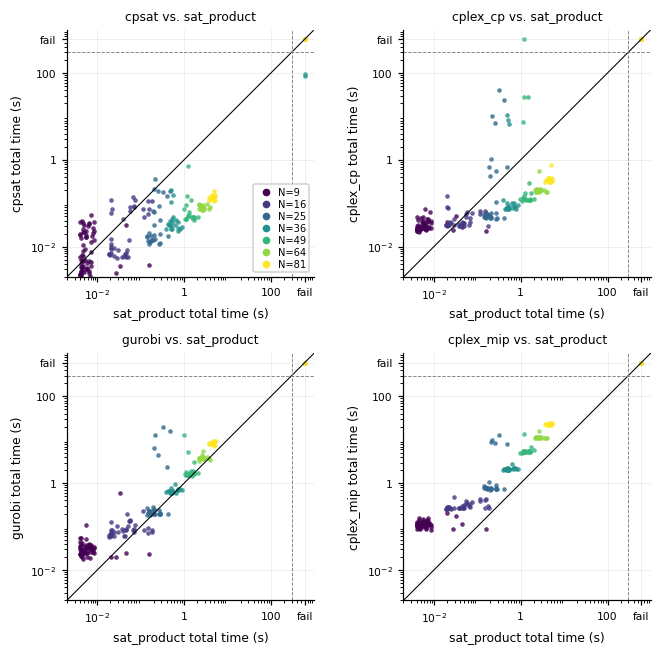

Đã lưu: D:\Study\Python\Sudoku_test\results\figures\scatter_loglog_pairs.pdf
   method  both solved  faster than sat_product  geo-mean ratio to sat_product
    cpsat          197                      151                           0.25
 cplex_cp          196                      103                           0.85
   gurobi          197                       25                           2.44
cplex_mip          197                        1                           7.76


In [25]:
p = d[d["m"].isin(B)].pivot_table(index=KEY, columns="m", values="y")
cN = {N: plt.get_cmap("viridis")(i / max(len(NS) - 1, 1)) for i, N in enumerate(NS)}
fig, axs = plt.subplots(2, 2, figsize=(6.3, 6.0))
for ax, o in zip(axs.flat, ["cpsat", "cplex_cp", "gurobi", "cplex_mip"]):
    for N in NS:
        idx = p.index.get_level_values("N") == N
        ax.scatter(p.loc[idx, "sat_product"], p.loc[idx, o], s=9, color=cN[N], alpha=.8, lw=0)
    lo, hi = 2e-3, 1000
    ax.plot([lo, hi], [lo, hi], color="k", lw=.7)
    ax.axvline(TIMEOUT, color="gray", ls="--", lw=.6); ax.axhline(TIMEOUT, color="gray", ls="--", lw=.6)
    ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlim(lo, hi); ax.set_ylim(lo, hi); ax.set_aspect("equal")
    tk, lb = [1e-2, 1, 100, FAIL_T], ["$10^{-2}$", "1", "100", "fail"]
    ax.set_xticks(tk); ax.set_xticklabels(lb); ax.set_yticks(tk); ax.set_yticklabels(lb)
    ax.set_xlabel("sat_product total time (s)"); ax.set_ylabel(f"{o} total time (s)")
    ax.set_title(f"{o} vs. sat_product")
axs.flat[0].legend(handles=[Line2D([0], [0], marker="o", ls="", color=cN[N], ms=4, label=f"N={N}") for N in NS],
                   loc="lower right", frameon=True, framealpha=.9, fontsize=6.5, borderpad=.3,
                   handletextpad=.2, labelspacing=.2)
fig.tight_layout(); save(fig, "scatter_loglog_pairs")

# Số instance mà mỗi phương pháp nhanh hơn sat_product (chỉ tính instance cả hai cùng giải)
ok = d[d["m"].isin(B)].pivot_table(index=KEY, columns="m", values="ok", aggfunc="first").astype(bool)
t  = d[d["m"].isin(B)].pivot_table(index=KEY, columns="m", values="tot")
rows = []
for o in ["cpsat", "cplex_cp", "gurobi", "cplex_mip"]:
    both = ok[o] & ok["sat_product"]
    rows.append({"method": o, "both solved": int(both.sum()),
                 "faster than sat_product": int((t.loc[both, o] < t.loc[both, "sat_product"]).sum()),
                 "geo-mean ratio to sat_product": round(float(np.exp(np.log(t.loc[both, o] / t.loc[both, "sat_product"]).mean())), 2)})
print(pd.DataFrame(rows).to_string(index=False))

## 3. Bảng số liệu

Các ô dưới đây tạo lại số liệu của Bảng 3–6 trong bài và lưu thành CSV trong `tables/`.

- **Bảng 3** — kích thước CNF của từng encoding, lấy từ cột `Vars`/`Constraints` với $\rho=0{,}3$, seed 1 (với $N$ cố định, các instance chỉ khác nhau ở các unit clause của gợi ý, nên đại diện cho mọi instance cùng cấp).
- **Bảng 4** — số instance giải được theo $N$, PAR2 và tỉ lệ thời gian trung vị so với encoding nhanh nhất trên từng instance ($N\ge 25$, chỉ lần giải được).
- **Bảng 5** — so sánh 5 phương pháp: số giải được/thất bại, PAR2, trung bình hình học (GM) trên cả 211 instance, và GM, trung vị, trung bình trên **tập chung** (196 instance).
- **Bảng 6** — các instance mà 5 phương pháp **không đồng nhất** về kết quả (`TO` = thất bại).

Công thức: $\mathrm{PAR2}=\frac1{|I|}\sum_i y_i$ với $y_i=t_i$ nếu giải được, $2T$ nếu không; $\mathrm{GM}=\exp\big(\frac1{|I|}\sum_i\ln y_i\big)$.

In [26]:
def par2(g):  return g["y"].mean()
def gmean(x): return float(np.exp(np.log(x).mean()))

# ---- Bảng 3: kích thước CNF (rho = 0.3, seed 1) ----
s3 = d[(d["hole"] == 0.3) & (d["Seed"] == 1) & d["m"].isin(SAT)]
ord3 = ["sat_product", "sat_commander", "sat_seqcounter", "sat_bitwise", "sat_pairwise"]
t3_vars = s3.pivot_table(index="N", columns="m", values="vars")[ord3].astype(int)
t3_cls  = s3.pivot_table(index="N", columns="m", values="cons")[ord3].astype(int)
t3_vars.to_csv(TAB / "table3_vars.csv"); t3_cls.to_csv(TAB / "table3_clauses.csv")
print("Bảng 3 - số biến:\n", t3_vars, "\n\nBảng 3 - số clause:\n", t3_cls)

# ---- Bảng 4: AMO encodings ----
Ns = NS
solved_N = (d[d["m"].isin(SAT)].groupby(["m", "N"])["ok"].sum().unstack().astype(int)
              .reindex(columns=Ns).loc[ord3])
s = d[d["m"].isin(SAT) & d["ok"] & (d["N"] >= 25)].pivot_table(index=KEY, columns="m", values="tot")
ratio_med = s.div(s.min(axis=1), axis=0).median()
t4 = solved_N.copy()
t4["Total/211"] = t4.sum(axis=1)
t4["PAR2"] = [round(par2(d[d["m"] == m]), 2) for m in t4.index]
t4["Median ratio"] = ratio_med.reindex(t4.index).round(3)
t4.to_csv(TAB / "table4_encodings.csv")
print("\nBảng 4:\n", t4)

# ---- Bảng 5: so sánh solver ----
okB = d[d["m"].isin(B)].pivot_table(index=KEY, columns="m", values="ok", aggfunc="first").astype(bool)
common = okB.index[okB.all(axis=1)]
tB = d[d["m"].isin(B)].pivot_table(index=KEY, columns="m", values="tot")
rows = []
for m in B:
    g = d[d["m"] == m]; c = tB.loc[common, m]
    rows.append({"method": m, "solved": int(g["ok"].sum()), "failed": int((~g["ok"]).sum()),
                 "PAR2": round(par2(g), 2), "GM": round(gmean(g["y"]), 3),
                 "GM (common)": round(gmean(c), 3), "median (common)": round(c.median(), 4),
                 "mean (common)": round(c.mean(), 3)})
t5 = pd.DataFrame(rows).sort_values("PAR2").set_index("method")
t5.to_csv(TAB / "table5_solvers.csv")
print(f"\nBảng 5 (tập chung = {len(common)} instance):\n", t5)

# ---- Bảng 6: instance không đồng nhất ----
diff = okB[~(okB.all(axis=1) | ~okB.any(axis=1))]
t6 = tB.where(okB).loc[diff.index, B].round(2).fillna("TO")
t6.to_csv(TAB / "table6_disagree.csv")
print(f"\nBảng 6 (cả 5 phương pháp không đồng nhất; {int((~okB.any(axis=1)).sum())} instance không ai giải):\n", t6)

Bảng 3 - số biến:
 m   sat_product  sat_commander  sat_seqcounter  sat_bitwise  sat_pairwise
N                                                                        
9          2673           1701            3321         2025           729
16        12288          12288           19456         8192          4096
25        65625          45625           75625        28125         15625
36       160704         129600          228096        77760         46656
49       367353         357749          578641       175273        117649
64       720896         802816         1294336       360448        262144
81      1318761        1554957         2630961       715149        531441 

Bảng 3 - số clause:
 m   sat_product  sat_commander  sat_seqcounter  sat_bitwise  sat_pairwise
N                                                                        
9          8157           7185            7833        12045         12045
16        46260          46260           46260        66740        124

## 4. Kiểm tra số liệu trích trong bài

Ô cuối đối chiếu các con số xuất hiện trong **Abstract, §4 và Conclusion** với dữ liệu vừa đọc. Mỗi dòng in `OK` hoặc `KHÁC`; nếu có `KHÁC` thì cần sửa lại câu tương ứng trong `main.tex` (hoặc kiểm tra xem CSV có bị thay đổi).

Các con số kiểm tra: tổng số lượt chạy và trạng thái; số instance giải bởi tất cả/không ai; số giải được và PAR2 của từng phương pháp; tỉ lệ thời gian trung vị của các encoding. Sai số làm tròn cho phép là một đơn vị ở chữ số cuối của số trích trong bài.

In [27]:
checks = []
def chk(name, got, want, tol=0.0):
    good = abs(got - want) <= tol
    checks.append(good)
    print(f"{'OK  ' if good else 'KHÁC'} {name:<42} dữ liệu = {got:<10} bài = {want}")

chk("Tổng số dòng", len(d), 1899)
chk("Số instance", n_inst, 211)
chk("Số lượt SOLVED", int(d['ok'].sum()), 1775)
chk("Số lượt TIMEOUT", int((d['st'] == 'TIMEOUT').sum()), 110)
chk("Số lượt UNSOLVED", int((d['st'] == 'UNSOLVED').sum()), 14)
chk("Instance giải bởi cả 5", len(common), 196)
chk("Instance không ai giải", int((~okB.any(axis=1)).sum()), 12)
for m, (sv, pr) in {"cpsat": (199, 35.01), "sat_product": (197, 40.56), "gurobi": (197, 41.33),
                    "cplex_mip": (197, 43.41), "cplex_cp": (196, 43.55)}.items():
    chk(f"{m}: số giải được", int(t5.loc[m, "solved"]), sv)
    chk(f"{m}: PAR2", float(t5.loc[m, "PAR2"]), pr, tol=0.006)
for m, r in {"sat_product": 1.034, "sat_seqcounter": 1.107, "sat_commander": 1.172,
             "sat_bitwise": 2.212, "sat_pairwise": 7.477}.items():
    chk(f"{m}: median ratio", float(t4.loc[m, "Median ratio"]), r, tol=0.0006)
print("\nTất cả khớp." if all(checks) else f"\nCó {checks.count(False)} chỗ KHÁC - xem các dòng ở trên.")

OK   Tổng số dòng                               dữ liệu = 1899       bài = 1899
OK   Số instance                                dữ liệu = 211        bài = 211
OK   Số lượt SOLVED                             dữ liệu = 1775       bài = 1775
OK   Số lượt TIMEOUT                            dữ liệu = 110        bài = 110
OK   Số lượt UNSOLVED                           dữ liệu = 14         bài = 14
OK   Instance giải bởi cả 5                     dữ liệu = 196        bài = 196
OK   Instance không ai giải                     dữ liệu = 12         bài = 12
OK   cpsat: số giải được                        dữ liệu = 199        bài = 199
OK   cpsat: PAR2                                dữ liệu = 35.01      bài = 35.01
OK   sat_product: số giải được                  dữ liệu = 197        bài = 197
OK   sat_product: PAR2                          dữ liệu = 40.56      bài = 40.56
OK   gurobi: số giải được                       dữ liệu = 197        bài = 197
OK   gurobi: PAR2                               

## 5. Ghi chú và cách tùy chỉnh

- **Đổi giới hạn thời gian**: sửa `TIMEOUT` ở §0; mọi mức phạt/vị trí `fail` tự cập nhật (`FAIL_T = 2 * TIMEOUT`). Nhãn tick `fail` của trục tung luôn trỏ vào `FAIL_T`.
- **Đổi SAT đại diện**: sửa `sat_product` trong danh sách `B` (và trong tiêu đề/nhãn Hình 6, Bảng 5) — nhưng khi đó cần chạy lại quy tắc chọn R1–R3 trong bài.
- **Kích thước hình** (`figsize`) được chọn cho cột đơn/đôi của mẫu `cas-sc` (rộng ≈ 6,3 in); đổi nếu mẫu khác.
- **Hạn chế dữ liệu** cần nhớ khi đọc hình: mỗi phương pháp chỉ chạy **một lần** trên mỗi instance; tập hole ratio và số seed **không đồng đều** giữa các $N$; các instance cùng $(N,\text{seed})$ **lồng nhau**; kết quả `SOLVED` chưa được kiểm chứng lại bằng bộ kiểm tra lưới; giới hạn 300 s bao gồm cả thời gian dựng với SAT nhưng chỉ tính thời gian giải với CP/MIP.